In [2]:
# Interactive File Upload and Ingestion
import pandas as pd
import numpy as np
import io
from google.colab import files

# Prompt the user to upload the CSV file from their computer
print("Please upload your 'heart_disease_uci.csv' file:")
uploaded = files.upload()

# Automatically grab the filename of the uploaded file
filename = list(uploaded.keys())[0]
print(f"\nSuccessfully uploaded: {filename}")

# Load dataset into pandas DataFrame
df = pd.read_csv(io.BytesIO(uploaded[filename]))
print(f"Dataset Shape: {df.shape}")

print("\nFirst 5 rows:")
display(df.head())

# Binarize target 'num': 0 means no heart disease, >0 means heart disease present
df['target'] = (df['num'] > 0).astype(int)
print("\nTarget Class Distribution:")
print(df['target'].value_counts(normalize=True))

Please upload your 'heart_disease_uci.csv' file:


Saving heart_disease_uci.csv to heart_disease_uci.csv

Successfully uploaded: heart_disease_uci.csv
Dataset Shape: (920, 16)

First 5 rows:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0



Target Class Distribution:
target
1    0.553261
0    0.446739
Name: proportion, dtype: float64


In [3]:
# EDA & Column Type Separation
print("Dataset Information:")
print(df.info())

print("\nMissing Values Check:")
print(df.isnull().sum())

# Drop unnecessary identifier and raw target columns
X = df.drop(columns=['id', 'dataset', 'num', 'target'])
y = df['target']

# Separate categorical and numerical features
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"\nCategorical Columns ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical Columns ({len(numerical_cols)}): {numerical_cols}")

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
 16  target    920 non-null    int64  
dtypes: float64(5), int64(4), object(8)
memory usage: 122.3+ KB
None

Missing Values Check:
id            0
age           0
sex      

In [4]:
# Stratified Train-Test Split
from sklearn.model_selection import train_test_split

# 80% training, 20% testing with stratification to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (736, 13)
Testing set shape: (184, 13)


In [5]:
# Cell 4: Data Preprocessing Pipeline (Handling Missing Values & Scaling)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical transformer: Impute missing values with median, then scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical transformer: Impute missing with most frequent, then one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine into a single column preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline successfully configured.")

Preprocessing pipeline successfully configured.


In [7]:
# Train and Evaluate Three Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score

# Define the three models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    clf = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    clf.fit(X_train, y_train)

    y_pred_proba = clf.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    results[name] = {
        'pipeline': clf,
        'probabilities': y_pred_proba,
        'roc_auc': roc_auc
    }
    print(f"{name} trained successfully. ROC-AUC: {roc_auc:.4f}")

Logistic Regression trained successfully. ROC-AUC: 0.9035
Random Forest trained successfully. ROC-AUC: 0.9200
Gradient Boosting trained successfully. ROC-AUC: 0.9116


In [8]:
# Threshold Tuning for High Recall (Clinical Priority)
# In clinical disease prediction, missing a diseased patient (False Negative) is far more costly
# than a False Alarm (False Positive). We lower the decision threshold to 0.35 to catch more cases.

from sklearn.metrics import confusion_matrix, recall_score, precision_score

decision_threshold = 0.35
evaluation_summary = []

for name, res in results.items():
    y_pred_proba = res['probabilities']
    y_pred_thresh = (y_pred_proba >= decision_threshold).astype(int)

    recall = recall_score(y_test, y_pred_thresh)
    precision = precision_score(y_test, y_pred_thresh)
    cm = confusion_matrix(y_test, y_pred_thresh)

    evaluation_summary.append({
        'Model': name,
        'ROC-AUC': res['roc_auc'],
        'Recall': recall,
        'Precision': precision,
        'False Negatives (Missed Cases)': cm[1][0],
        'False Positives (False Alarms)': cm[0][1]
    })

    print(f"\n================ {name} (Threshold = {decision_threshold}) ================")
    print(f"Recall (Sensitivity): {recall:.4f}")
    print(f"Precision: {precision:.4f}")
    print("Confusion Matrix:\n", cm)

summary_df = pd.DataFrame(evaluation_summary)
print("\n--- Final Model Comparison Summary ---")
display(summary_df)


================ Logistic Regression (Threshold = 0.35) ================
Recall (Sensitivity): 0.9118
Precision: 0.7881
Confusion Matrix:
 [[57 25]
 [ 9 93]]

================ Random Forest (Threshold = 0.35) ================
Recall (Sensitivity): 0.9608
Precision: 0.7778
Confusion Matrix:
 [[54 28]
 [ 4 98]]

================ Gradient Boosting (Threshold = 0.35) ================
Recall (Sensitivity): 0.9510
Precision: 0.7886
Confusion Matrix:
 [[56 26]
 [ 5 97]]

--- Final Model Comparison Summary ---


,Model,ROC-AUC,Recall,Precision,False Negatives (Missed Cases),False Positives (False Alarms)
0,Logistic Regression,0.903515,0.911765,0.788136,9,25
1,Random Forest,0.919955,0.960784,0.777778,4,28
2,Gradient Boosting,0.911645,0.950980,0.788618,5,26


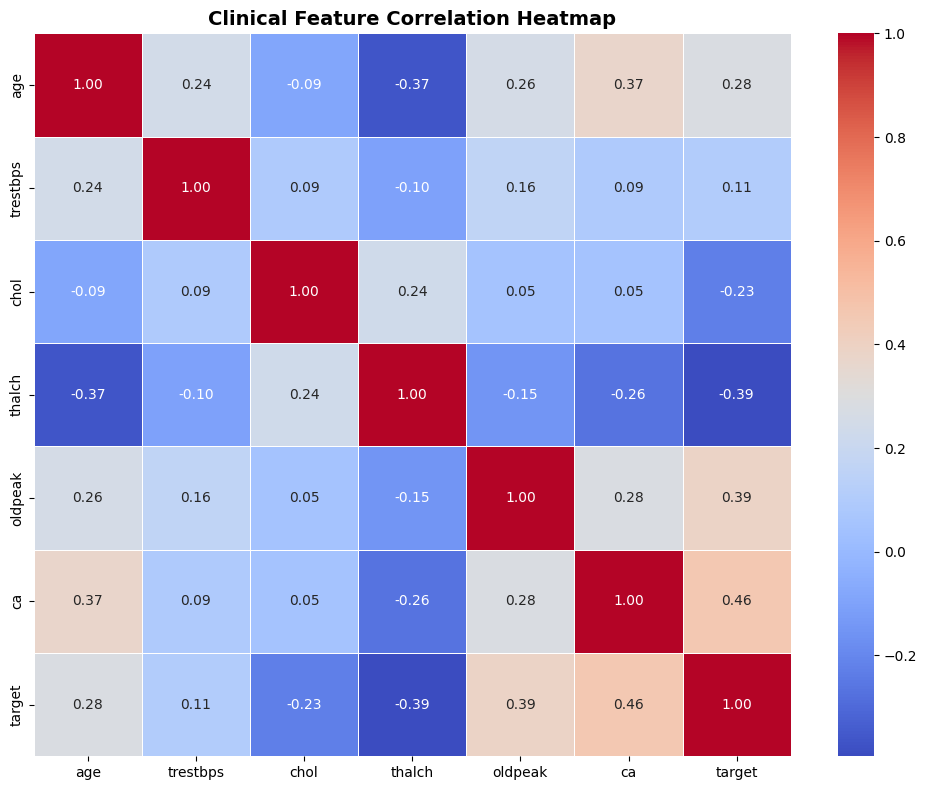

In [9]:
# Feature Correlation Heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
# Compute correlation matrix on numerical features + target
corr_df = X.copy()
corr_df['target'] = y
corr_matrix = corr_df.select_dtypes(include=['int64', 'float64']).corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("Clinical Feature Correlation Heatmap", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

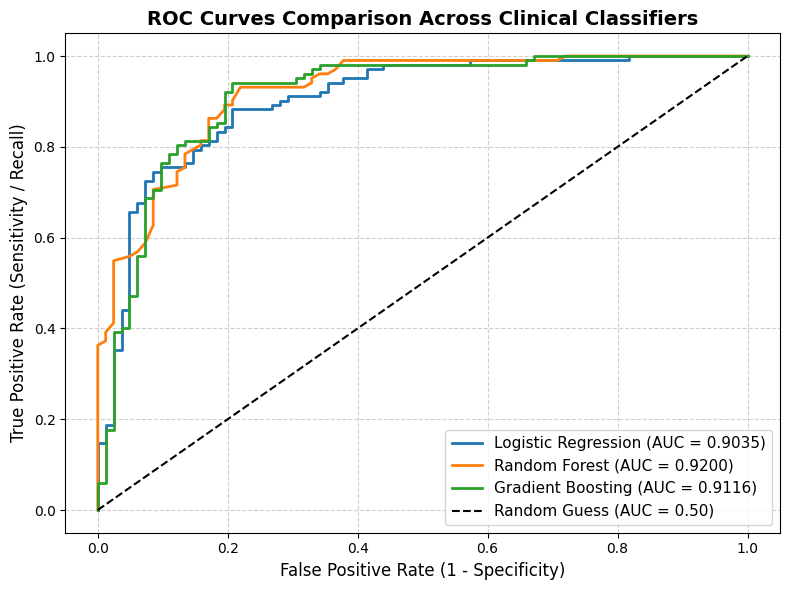

In [10]:
# Cell 8: Comparative ROC Curves Visualization
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, res in results.items():
    y_pred_proba = res['probabilities']
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {res['roc_auc']:.4f})", linewidth=2)

# Plot diagonal reference line for random guessing
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.50)")

plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
plt.title("ROC Curves Comparison Across Clinical Classifiers", fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()